# Experiment E2: Fixed-size vs Article-level Chunking

## Objective
Compare two document chunking strategies for legal information retrieval
using the existing BM25 implementation.

1. Article-level: one complete legal article per retrieval unit.
2. Fixed-size: split each legal article into fixed-size word chunks.

Evaluation metrics:
- Top-1 Accuracy
- Recall@5
- MRR@5

In [8]:
from pathlib import Path
import sys
import re
import json
import unicodedata

import numpy as np
import pandas as pd
from rank_bm25 import BM25Okapi

# إعدادات تجربة E2
CHUNK_SIZE = 200
CHUNK_OVERLAP = 40
TOP_K = 5

# العثور على مجلد المشروع
def find_project_root(start):
    for folder in [start, *start.parents]:
        if (folder / "src" / "retrieval" / "bm25_retrieval.py").exists():
            return folder

    raise FileNotFoundError(
        "لم أجد ملف src/retrieval/bm25_retrieval.py. "
        "تأكدي أنك تعملين داخل مشروع PDPL-Compliance-Copilot."
    )

PROJECT_ROOT = find_project_root(Path.cwd())

# استيراد الدوال من محرك BM25 الموجود
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from retrieval.bm25_retrieval import (
    load_legal_documents,
    tokenize,
)

GOLD_PATH = PROJECT_ROOT / "data" / "evaluation" / "gold_qa_set.csv"
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"

print("Project root:", PROJECT_ROOT)
print("Gold dataset exists:", GOLD_PATH.exists())
print("Chunk size:", CHUNK_SIZE)
print("Chunk overlap:", CHUNK_OVERLAP)

Project root: c:\Users\Anfal\OneDrive\المستندات\GitHub\PDPL-Compliance-Copilot
Gold dataset exists: True
Chunk size: 200
Chunk overlap: 40


In [9]:
# تحميل المواد القانونية باستخدام الدالة الموجودة
documents = load_legal_documents()

# تحميل مجموعة الأسئلة المرجعية
if not GOLD_PATH.exists():
    raise FileNotFoundError(
        f"Evaluation dataset not found: {GOLD_PATH}"
    )

gold = pd.read_csv(GOLD_PATH, encoding="utf-8-sig")

print("Number of legal documents:", len(documents))
print("Number of evaluation questions:", len(gold))

print("\nAvailable document fields:")
print(list(documents[0].keys()))

print("\nEvaluation columns:")
print(list(gold.columns))

display(pd.DataFrame(documents).head(3))
display(gold.head(3))

Number of legal documents: 180
Number of evaluation questions: 60

Available document fields:
['document_id', 'language', 'article_number', 'article_title', 'article_text', 'source', 'source_file', 'source_line_start']

Evaluation columns:
['question_id', 'question', 'language', 'question_type', 'reference_answer', 'answerable_from_sources', 'source_document', 'article_number', 'supporting_text', 'expected_behavior']


,document_id,language,article_number,article_title,article_text,source,source_file,source_line_start
0,pdpl_ar,ar,1,,المادة الأولى:\nلغرض تطبيق هذا النظام، يُقصد ب...,pdpl,pdpl_ar_articles.csv,12
1,pdpl_ar,ar,2,,المادة الثانية:\n1- يُطبق النظام على أي عملية ...,pdpl,pdpl_ar_articles.csv,37
2,pdpl_ar,ar,3,,المادة الثالثة:\nلا تخل الأحكام والإجراءات الم...,pdpl,pdpl_ar_articles.csv,41


,question_id,question,language,question_type,reference_answer,answerable_from_sources,source_document,article_number,supporting_text,expected_behavior
0,Q001,ما المقصود بالبيانات الشخصية في نظام حماية الب...,ar,direct,البيانات الشخصية هي كل بيان، مهما كان مصدره أو...,True,pdpl_ar,1.0,المادة الأولى:\r\nلغرض تطبيق هذا النظام، يُقصد...,answer_with_citation
1,Q002,شركة خارج المملكة تعالج بيانات شخصية لأشخاص مق...,ar,scenario,نعم، يشمل نطاق تطبيق النظام معالجة البيانات ال...,True,pdpl_ar,2.0,المادة الثانية:\r\n1- يُطبق النظام على أي عملي...,answer_with_citation
2,Q003,هل تُستثنى معالجة الفرد للبيانات لأغراض شخصية ...,ar,direct,لا. يرد الاستثناء إذا كانت المعالجة لأغراض لا ...,True,pdpl_ar,2.0,المادة الثانية:\r\n1- يُطبق النظام على أي عملي...,answer_with_citation


In [10]:
required_columns = [
    "question",
    "language",
    "answerable_from_sources",
    "source_document",
    "article_number",
]

missing_columns = [
    column for column in required_columns
    if column not in gold.columns
]

if missing_columns:
    raise ValueError(f"Missing evaluation columns: {missing_columns}")

print("Evaluation dataset structure looks correct.")

print("\nQuestions by language:")
display(
    gold.groupby("language")
    .size()
    .rename("count")
    .reset_index()
)

print("\nAnswerability values:")
display(
    gold["answerable_from_sources"]
    .value_counts(dropna=False)
    .rename_axis("value")
    .reset_index(name="count")
)

Evaluation dataset structure looks correct.

Questions by language:


,language,count
0,ar,42
1,en,18



Answerability values:


,value,count
0,True,50
1,False,10


In [11]:

def make_chunks(documents, strategy):
    chunks = []

    for doc in documents:
        text = str(doc.get("article_text") or "").strip()
        title = str(doc.get("article_title") or "").strip()
        article_no = str(doc["article_number"]).removesuffix(".0")
        language = str(doc.get("language", "")).lower()
        source = str(doc.get("source", ""))

        # Add article identity to every searchable chunk
        if language == "ar":
            prefix = f"المادة {article_no} | المصدر {source}"
        else:
            prefix = f"Article {article_no} | Source {source}"

        header = "\n".join(
            part for part in [prefix, title] if part
        )

        if strategy == "article":
            # One complete article per chunk
            if not text and not title:
                continue

            chunk = doc.copy()
            chunk["chunk_id"] = (
                f"{doc['source_file']}_{article_no}_article"
            )
            chunk["chunk_index"] = 0
            chunk["chunk_text"] = "\n".join(
                part for part in [header, text] if part
            )
            chunks.append(chunk)

        elif strategy == "fixed":
            # Fixed-size chunks with overlap
            words = text.split()

            if not words:
                if title:
                    chunk = doc.copy()
                    chunk["chunk_id"] = (
                        f"{doc['source_file']}_{article_no}_0"
                    )
                    chunk["chunk_index"] = 0
                    chunk["chunk_text"] = header
                    chunks.append(chunk)
                continue

            start = 0
            chunk_index = 0
            step = CHUNK_SIZE - CHUNK_OVERLAP

            while start < len(words):
                end = min(start + CHUNK_SIZE, len(words))
                text_part = " ".join(words[start:end])

                chunk = doc.copy()
                chunk["chunk_id"] = (
                    f"{doc['source_file']}_{article_no}_{chunk_index}"
                )
                chunk["chunk_index"] = chunk_index
                chunk["chunk_text"] = "\n".join(
                    part for part in [header, text_part] if part
                )
                chunks.append(chunk)

                # Stop when the end of the article is reached
                if end == len(words):
                    break

                start += step
                chunk_index += 1

        else:
            raise ValueError(
                "strategy must be 'article' or 'fixed'"
            )

    return chunks


# Recreate both strategies
article_chunks = make_chunks(documents, "article")
fixed_chunks = make_chunks(documents, "fixed")

print("Original articles:", len(documents))
print("Article-level chunks:", len(article_chunks))
print("Fixed-size chunks:", len(fixed_chunks))

print("\nFixed-size sample:")
display(
    pd.DataFrame(fixed_chunks)[
        [
            "language",
            "source",
            "article_number",
            "chunk_index",
            "chunk_text",
        ]
    ].head(3)
)


Original articles: 180
Article-level chunks: 180
Fixed-size chunks: 239

Fixed-size sample:


,language,source,article_number,chunk_index,chunk_text
0,ar,pdpl,1,0,المادة 1 | المصدر pdpl\nالمادة الأولى: لغرض تط...
1,ar,pdpl,1,1,المادة 1 | المصدر pdpl\nالنظام، سواء من صاحبها...
2,ar,pdpl,1,2,المادة 1 | المصدر pdpl\nأو الصحية لذلك الشخص، ...


In [12]:

def normalize_language(value):
    value = str(value).strip().lower()

    if value in {"ar", "arabic", "العربية"}:
        return "ar"
    if value in {"en", "english", "الإنجليزية"}:
        return "en"

    return value


def build_chunk_indexes(chunks):
    indexes = {}

    for language in ["ar", "en"]:
        language_chunks = [
            chunk for chunk in chunks
            if normalize_language(chunk.get("language")) == language
        ]

        valid_chunks = []
        tokenized_chunks = []

        for chunk in language_chunks:
            tokens = tokenize(chunk["chunk_text"])

            if tokens:
                valid_chunks.append(chunk)
                tokenized_chunks.append(tokens)

        if valid_chunks:
            indexes[language] = {
                "bm25": BM25Okapi(tokenized_chunks),
                "chunks": valid_chunks,
            }

    return indexes


# Build separate indexes for both chunking strategies
article_indexes = build_chunk_indexes(article_chunks)
fixed_indexes = build_chunk_indexes(fixed_chunks)

# Show how many chunks were indexed
rows = []

for strategy, indexes in [
    ("Article-level", article_indexes),
    ("Fixed-size", fixed_indexes),
]:
    for language, data in indexes.items():
        rows.append({
            "strategy": strategy,
            "language": language,
            "indexed_chunks": len(data["chunks"]),
        })

display(pd.DataFrame(rows))


,strategy,language,indexed_chunks
0,Article-level,ar,90
1,Article-level,en,90
2,Fixed-size,ar,114
3,Fixed-size,en,125



##  Retrieval Sanity Check

### Objective
Verify that both BM25 retrieval strategies return relevant legal articles before running the full evaluation.

### Method
- Use the same answerable question from the gold evaluation dataset.
- Search using the Article-level and Fixed-size BM25 indexes.
- Select the index that matches the question language.
- Retrieve the top 5 unique legal articles.
- Remove duplicate results that belong to the same source document and article number.

### Expected Outcome
Display the retrieved articles, their BM25 scores, and their text for both strategies. Compare the retrieved article numbers with the expected reference article.

**Note:** This is an initial sanity check, not the final E2 evaluation. Overall performance will be measured later using Top-1 Accuracy, Recall@5, and MRR@5 on the answerable evaluation questions.


In [13]:
def retrieve_articles(query, indexes, language, top_k=5):
    language = normalize_language(language)

    if language not in indexes:
        return []

    data = indexes[language]
    query_tokens = tokenize(query)

    if not query_tokens:
        return []

    scores = data["bm25"].get_scores(query_tokens)
    ranked_indices = np.argsort(scores)[::-1]

    results = []
    seen_articles = set()

    for idx in ranked_indices:
        chunk = data["chunks"][idx]

        # Identify the original legal article
        article_key = (
            chunk["source_file"],
            str(chunk["article_number"]).removesuffix(".0"),
        )

        if article_key in seen_articles:
            continue

        seen_articles.add(article_key)

        result = chunk.copy()
        result["score"] = float(scores[idx])
        results.append(result)

        if len(results) == top_k:
            break

    return results


# Test both strategies using the same answerable question
test_row = gold[gold["answerable_from_sources"] == True].iloc[0]

query = test_row["question"]
language = normalize_language(test_row["language"])

article_results = retrieve_articles(
    query, article_indexes, language
)
fixed_results = retrieve_articles(
    query, fixed_indexes, language
)

print("Test question:", query)
print("Expected source:", test_row["source_document"])
print("Expected article:", test_row["article_number"])

print("\nArticle-level results:")
display(pd.DataFrame(article_results)[
    ["source", "article_number", "score", "chunk_text"]
])

print("\nFixed-size results:")
display(pd.DataFrame(fixed_results)[
    ["source", "article_number", "score", "chunk_text"]
])


Test question: ما المقصود بالبيانات الشخصية في نظام حماية البيانات الشخصية السعودي؟
Expected source: pdpl_ar
Expected article: 1.0

Article-level results:


,source,article_number,score,chunk_text
0,implementing,32,12.743928,المادة 32 | المصدر implementing\nمسؤول حماية ا...
1,pdpl,2,11.715560,المادة 2 | المصدر pdpl\nالمادة الثانية:\n1- يُ...
2,pdpl,15,11.205551,المادة 15 | المصدر pdpl\nالمادة الخامسة عشرة:\...
3,implementing,24,11.079927,المادة 24 | المصدر implementing\nالإشعار عن حو...
4,pdpl,10,10.945555,المادة 10 | المصدر pdpl\nالمادة العاشرة:\nلا ي...



Fixed-size results:


,source,article_number,score,chunk_text
0,implementing,32,12.825938,المادة 32 | المصدر implementing\nمسؤول حماية ا...
1,implementing,24,10.920799,المادة 24 | المصدر implementing\nالإشعار عن حو...
2,pdpl,3,10.815786,المادة 3 | المصدر pdpl\nالمادة الثالثة: لا تخل...
3,pdpl,2,10.752241,المادة 2 | المصدر pdpl\nالمادة الثانية: 1- يُط...
4,implementing,4,10.698320,المادة 4 | المصدر implementing\nالحق في العلم\...


In [14]:

def check_expected_article(query, indexes, language, expected_source_file, expected_article):
    data = indexes[normalize_language(language)]
    tokens = tokenize(query)
    scores = data["bm25"].get_scores(tokens)
    ranked_indices = np.argsort(scores)[::-1]

    seen = set()
    article_rank = None
    article_score = None

    for idx in ranked_indices:
        chunk = data["chunks"][idx]

        number = str(chunk["article_number"]).removesuffix(".0")
        key = (chunk["source_file"], number)

        if key in seen:
            continue

        seen.add(key)

        if (
            chunk["source_file"] == expected_source_file
            and number == str(expected_article).removesuffix(".0")
        ):
            article_rank = len(seen)
            article_score = float(scores[idx])
            break

    return {
        "expected_article": expected_article,
        "rank": article_rank,
        "score": article_score,
    }


for name, indexes in [
    ("Article-level", article_indexes),
    ("Fixed-size", fixed_indexes),
]:
    result = check_expected_article(
        query=query,
        indexes=indexes,
        language=language,
        expected_source_file="pdpl_ar_articles.csv",
        expected_article=1,
    )
    print(name, result)


Article-level {'expected_article': 1, 'rank': 23, 'score': 8.08169010671044}
Fixed-size {'expected_article': 1, 'rank': 15, 'score': 8.877172770541016}



## Validate Gold References

### Objective
Verify that every answerable question in the gold evaluation dataset matches an existing legal document and article number.

### Method
- Select questions marked as answerable from the legal sources.
- Normalize source identifiers and article numbers to avoid mismatches caused by different data types or formatting.
- Match each question's reference source and article number against the loaded legal documents.
- Report matched and unmatched questions before calculating retrieval metrics.

### Expected Outcome
Confirm that all 50 answerable questions have valid reference articles.

**Note:** Questions with unmatched references must be investigated before the final E2 evaluation to avoid misleading retrieval metrics.


In [15]:

def normalize_article_number(value):
    if pd.isna(value):
        return None

    value = str(value).strip()

    if value.endswith(".0"):
        value = value[:-2]

    return value


def normalize_source(value):
    if pd.isna(value):
        return None

    return str(value).strip().lower()


# Create reference keys from the loaded legal documents
document_keys = {
    (
        normalize_source(doc.get("document_id")),
        normalize_article_number(doc.get("article_number")),
    )
    for doc in documents
}

# Select answerable questions
answerable = gold[
    gold["answerable_from_sources"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["true", "1", "yes"])
].copy()

# Normalize the reference fields
answerable["source_key"] = answerable["source_document"].apply(
    normalize_source
)
answerable["article_key"] = answerable["article_number"].apply(
    normalize_article_number
)

# Check whether each reference exists in the legal corpus
answerable["source_article_found"] = answerable.apply(
    lambda row: (
        row["source_key"],
        row["article_key"],
    ) in document_keys,
    axis=1,
)

matched_count = int(answerable["source_article_found"].sum())
unmatched_count = len(answerable) - matched_count

print("Total gold questions:", len(gold))
print("Answerable questions:", len(answerable))
print("Matched references:", matched_count)
print("Unmatched references:", unmatched_count)

print("\nGold source names:")
display(
    gold["source_document"]
    .value_counts(dropna=False)
    .rename_axis("source_document")
    .reset_index(name="count")
)

print("\nUnmatched answerable questions:")
display(
    answerable.loc[
        ~answerable["source_article_found"],
        [
            "question_id",
            "source_document",
            "article_number",
            "language",
        ],
    ]
)


Total gold questions: 60
Answerable questions: 50
Matched references: 50
Unmatched references: 0

Gold source names:


,source_document,count
0,pdpl_ar,16
1,implementing_ar,16
2,NaN,10
3,transfer_en,6
4,pdpl_en,5
5,implementing_en,5
6,transfer_ar,2



Unmatched answerable questions:


,question_id,source_document,article_number,language



##  Evaluate Retrieval Performance

### Objective
Compare fixed-size chunking and article-level chunking using the same 50 answerable questions.

### Evaluation Metrics
- **Top-1 Accuracy:** Percentage of questions where the correct source article ranks first.
- **Recall@5:** Percentage of questions where the correct source article appears within the top five results.
- **MRR@5:** Average reciprocal rank of the correct source article within the top five results. Questions where the correct article is not in the top five receive a score of zero.

### Method
Evaluate both chunking strategies on the same questions and compare their retrieval metrics.

### Expected Outcome
A fair comparison of retrieval performance for both chunking strategies.


In [16]:

def normalize_article_number(value):
    if pd.isna(value):
        return None
    value = str(value).strip()
    return value[:-2] if value.endswith(".0") else value


answerable = gold[
    gold["answerable_from_sources"]
    .astype(str).str.strip().str.lower()
    .isin(["true", "1", "yes"])
].copy()

evaluation_rows = []

for _, row in answerable.iterrows():
    language = normalize_language(row["language"])
    query = row["question"]

    expected_source = str(row["source_document"]).strip()
    expected_article = normalize_article_number(row["article_number"])

    for strategy, indexes in [
        ("article-level", article_indexes),
        ("fixed-size", fixed_indexes),
    ]:
        results = retrieve_articles(
            query, indexes, language, top_k=TOP_K
        )

        reciprocal_rank = 0.0
        correct_rank = None

        for rank, result in enumerate(results, start=1):
            result_source = str(result.get("document_id", "")).strip()
            result_article = normalize_article_number(
                result.get("article_number")
            )

            if (
                result_source == expected_source
                and result_article == expected_article
            ):
                correct_rank = rank
                reciprocal_rank = 1.0 / rank
                break

        evaluation_rows.append({
            "question_id": row["question_id"],
            "language": language,
            "strategy": strategy,
            "expected_source": expected_source,
            "expected_article": expected_article,
            "correct_rank": correct_rank,
            "top1_accuracy": int(correct_rank == 1),
            "recall_at_5": int(correct_rank is not None),
            "mrr_at_5": reciprocal_rank,
        })

evaluation_results = pd.DataFrame(evaluation_rows)

print("Questions evaluated:", answerable.shape[0])
print("Evaluation rows:", len(evaluation_results))
display(evaluation_results.head())


Questions evaluated: 50
Evaluation rows: 100


,question_id,language,strategy,expected_source,expected_article,correct_rank,top1_accuracy,recall_at_5,mrr_at_5
0,Q001,ar,article-level,pdpl_ar,1,NaN,0,0,0.00
1,Q001,ar,fixed-size,pdpl_ar,1,NaN,0,0,0.00
2,Q002,ar,article-level,pdpl_ar,2,4.0,0,1,0.25
3,Q002,ar,fixed-size,pdpl_ar,2,NaN,0,0,0.00
4,Q003,ar,article-level,pdpl_ar,2,2.0,0,1,0.50


In [17]:

# Check whether any evaluation metrics are unexpectedly missing
print("Missing values in each column:")
display(evaluation_results.isna().sum())

# Summarize the three retrieval metrics by strategy
summary = (
    evaluation_results
    .groupby("strategy")
    .agg(
        Top1_Accuracy=("top1_accuracy", "mean"),
        Recall_at_5=("recall_at_5", "mean"),
        MRR_at_5=("mrr_at_5", "mean"),
    )
    .reset_index()
)

# Convert Top-1 Accuracy and Recall@5 to percentages
summary["Top1_Accuracy"] *= 100
summary["Recall_at_5"] *= 100

print("\nOverall retrieval comparison:")
display(summary.round(4))


Missing values in each column:


question_id          0
language             0
strategy             0
expected_source      0
expected_article     0
correct_rank        25
top1_accuracy        0
recall_at_5          0
mrr_at_5             0
dtype: int64


Overall retrieval comparison:


,strategy,Top1_Accuracy,Recall_at_5,MRR_at_5
0,article-level,40.0,78.0,0.5573
1,fixed-size,42.0,72.0,0.5523



### Retrieval Performance by Language

#### Objective
Compare fixed-size and article-level chunking separately for Arabic and English questions.

#### Method
Calculate Top-1 Accuracy, Recall@5, and MRR@5 for each strategy within each language.

#### Expected Outcome
Identify whether the effect of chunking strategy differs between Arabic and English retrieval.


In [18]:

by_language = (
    evaluation_results
    .groupby(["language", "strategy"])
    .agg(
        Questions=("question_id", "nunique"),
        Top1_Accuracy=("top1_accuracy", "mean"),
        Recall_at_5=("recall_at_5", "mean"),
        MRR_at_5=("mrr_at_5", "mean"),
    )
    .reset_index()
)

by_language["Top1_Accuracy"] *= 100
by_language["Recall_at_5"] *= 100

print("Retrieval performance by language:")
display(by_language.round(4))


Retrieval performance by language:


,language,strategy,Questions,Top1_Accuracy,Recall_at_5,MRR_at_5
0,ar,article-level,34,32.3529,76.4706,0.5083
1,ar,fixed-size,34,35.2941,70.5882,0.5083
2,en,article-level,16,56.2500,81.2500,0.6615
3,en,fixed-size,16,56.2500,75.0000,0.6458



#### Save E2 Evaluation Results

##### Objective
Save the overall comparison, language-level comparison, and per-question retrieval results.

##### Output Files
- `e2_evaluation_summary.csv`
- `e2_evaluation_by_language.csv`
- `e2_evaluation_results.csv`


In [19]:

# Create the output directory if it does not exist
OUTPUT_DIR = PROJECT_ROOT / "data" / "evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save all three evaluation tables
summary_path = OUTPUT_DIR / "e2_evaluation_summary.csv"
language_path = OUTPUT_DIR / "e2_evaluation_by_language.csv"
results_path = OUTPUT_DIR / "e2_evaluation_results.csv"

summary.to_csv(summary_path, index=False, encoding="utf-8-sig")
by_language.to_csv(language_path, index=False, encoding="utf-8-sig")
evaluation_results.to_csv(results_path, index=False, encoding="utf-8-sig")

print("E2 evaluation files saved successfully:")
print(f"1. {summary_path}")
print(f"2. {language_path}")
print(f"3. {results_path}")

print("\nRows saved:")
print("Overall summary:", len(summary))
print("Language comparison:", len(by_language))
print("Per-question results:", len(evaluation_results))


E2 evaluation files saved successfully:
1. c:\Users\Anfal\OneDrive\المستندات\GitHub\PDPL-Compliance-Copilot\data\evaluation\e2_evaluation_summary.csv
2. c:\Users\Anfal\OneDrive\المستندات\GitHub\PDPL-Compliance-Copilot\data\evaluation\e2_evaluation_by_language.csv
3. c:\Users\Anfal\OneDrive\المستندات\GitHub\PDPL-Compliance-Copilot\data\evaluation\e2_evaluation_results.csv

Rows saved:
Overall summary: 2
Language comparison: 4
Per-question results: 100


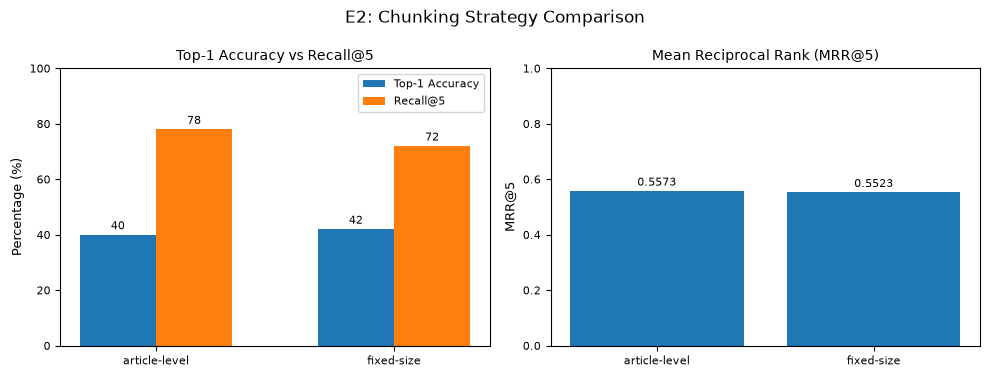

In [21]:

import matplotlib.pyplot as plt
import numpy as np

plot_data = summary.set_index("strategy")
strategies = ["article-level", "fixed-size"]
x = np.arange(len(strategies))
width = 0.32

# Create two smaller charts side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

# Chart 1: Top-1 Accuracy and Recall@5
ax = axes[0]

top1 = plot_data.loc[strategies, "Top1_Accuracy"].to_numpy()
recall = plot_data.loc[strategies, "Recall_at_5"].to_numpy()

bars1 = ax.bar(x - width / 2, top1, width, label="Top-1 Accuracy")
bars2 = ax.bar(x + width / 2, recall, width, label="Recall@5")

ax.set_title("Top-1 Accuracy vs Recall@5", fontsize=10)
ax.set_ylabel("Percentage (%)", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(strategies, fontsize=8)
ax.set_ylim(0, 100)
ax.tick_params(axis="y", labelsize=8)
ax.legend(fontsize=8)
ax.bar_label(bars1, fmt="%.0f", fontsize=8, padding=2)
ax.bar_label(bars2, fmt="%.0f", fontsize=8, padding=2)

# Chart 2: MRR@5
ax = axes[1]

mrr = plot_data.loc[strategies, "MRR_at_5"].to_numpy()
bars = ax.bar(strategies, mrr)

ax.set_title("Mean Reciprocal Rank (MRR@5)", fontsize=10)
ax.set_ylabel("MRR@5", fontsize=9)
ax.set_ylim(0, 1)
ax.tick_params(axis="both", labelsize=8)
ax.bar_label(bars, fmt="%.4f", fontsize=8, padding=2)

# Main title and spacing
fig.suptitle("E2: Chunking Strategy Comparison", fontsize=12)
plt.tight_layout()
plt.show()
